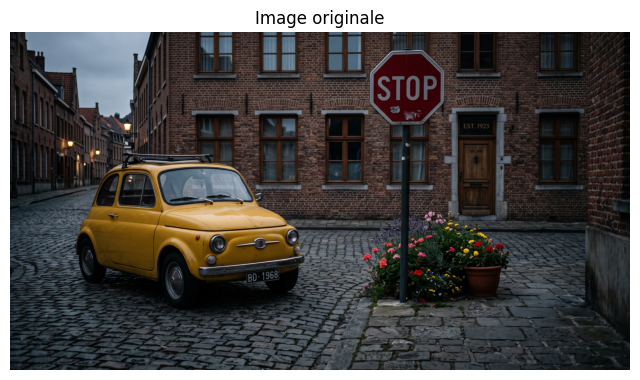

Dimensions : (1536, 2816, 3)


In [6]:
import cv2 
import numpy as np 
import matplotlib.pyplot as plt 
 
from sklearn.cluster import KMeans 
from sklearn.mixture import GaussianMixture 
import skfuzzy as fuzz 
 
image = cv2.imread("image.jpg") 
 
if image is None: 
    raise ValueError("Impossible de charger l'image.") 
 
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB) 
 
plt.figure(figsize=(8, 5)) 
plt.imshow(image) 
plt.title("Image originale") 
plt.axis("off") 
plt.show() 
 
print("Dimensions :", image.shape) 

In [7]:
pixels = image.reshape((-1, 3)) 
pixels = np.float32(pixels) 
 
print("Nombre de pixels :", pixels.shape[0]) 
print("Nombre de caractéristiques :", pixels.shape[1])  

Nombre de pixels : 4325376
Nombre de caractéristiques : 3


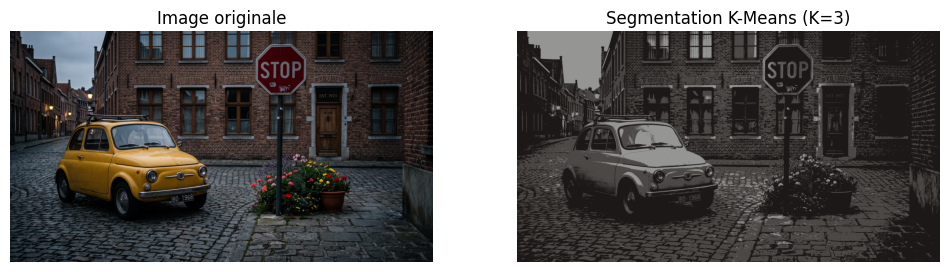

In [8]:
k = 3 
 
kmeans = KMeans( 
    n_clusters=k, 
    random_state=42, 
    n_init=10 
) 
 
labels_kmeans = kmeans.fit_predict(pixels) 
centres = np.uint8(kmeans.cluster_centers_) 
 
image_kmeans = centres[labels_kmeans] 
image_kmeans = image_kmeans.reshape(image.shape) 
 
plt.figure(figsize=(12, 5)) 
plt.subplot(1, 2, 1) 
plt.imshow(image) 
plt.title("Image originale") 
plt.axis("off") 
 
plt.subplot(1, 2, 2) 
plt.imshow(image_kmeans) 
plt.title("Segmentation K-Means (K=3)") 
plt.axis("off") 
plt.show() 

In [10]:
valeurs_k = [2, 3, 5, 8] 
 
plt.figure(figsize=(14, 8)) 
for i, k in enumerate(valeurs_k): 
    modele = KMeans(n_clusters=k, random_state=42, n_init=10) 
    labels = modele.fit_predict(pixels) 
    centres = np.uint8(modele.cluster_centers_)

<Figure size 1400x800 with 0 Axes>